In [1]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
from enigmatoolbox.utils.parcellation import parcel_to_surface
import nilearn.plotting

import sys
sys.path.append('..')

from helper.func import general_linear_model

In [5]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))

In [6]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

my_rdbu = LinearSegmentedColormap.from_list(
    "my_rdbu", ["#174fa0", "#2f89c2", "#f7f7f7", "#df5948", "#ad0c28"], N=256)

try:
    mpl.colormaps.register(my_rdbu)
except ValueError:
    pass

## ENIGMA dataset

In [ ]:
data_dir = os.path.join(project_dir, 'data', 'ENIGMA_data')
results_dir = os.path.join(project_dir, 'results', 'ENIGMA_results')

demo = pd.read_csv(os.path.join(results_dir, '...', 'data_combat', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'data_combat', 'ctx_tle.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'data_combat', 'sv_tle.csv'), index_col=0)


### Effect of diagnosis-sex interaction across cohorts

In [11]:
## GLM comparison — TLE only

biomarker_datasets = {'ctx': {'tle': ctx_tle}, 'sv': {'tle': sv_tle}}
comparison_types = ['sex_group_interaction']

results = {}

for epi in ['tle']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():

        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type,
                age_col="Age", sex_col="Sex", icv_col="ICV", group_col="Dx"
            )

2026-09-02 16:46:33,711 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 16:46:33,717 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 16:46:33,719 - brainstat - WARNING - interact has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 16:46:34,008 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical va

In [12]:
# Reorganize results

epi_types = ['tle']
biomarkers = ['ctx', 'sv']

comparison_types = ['sex_group_interaction']

metric_map = {
    't': 't_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f'{metric_name}_{epi}_{biomarker}'] = values

In [ ]:
# ## Save 

metrics_to_save = ['t', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'TLE')
os.makedirs(output_base, exist_ok=True)

for biomarker in biomarkers:
    index_cols = biomarker_index_map[biomarker]

    for metric in metrics_to_save:
        key = f'{metric}_tle_{biomarker}'

        if key not in result_dicts:
            continue

        values_all = result_dicts[key]
        values = values_all[0, :]

        df = pd.DataFrame(values, index=index_cols, columns=[f'{metric}_value'])
        df['analysis'] = 'sex × diagnosis interaction'
        df['interaction'] = 'sex × diagnosis'
        df['diagnosis'] = 'TLE'
        df['metric'] = metric
        df['biomarker'] = biomarker

        out_name = f'{metric}_{biomarker}.csv'
        df.to_csv(os.path.join(output_base, out_name), index=True)

Sex effects in interaction in cortical thickness in TLE

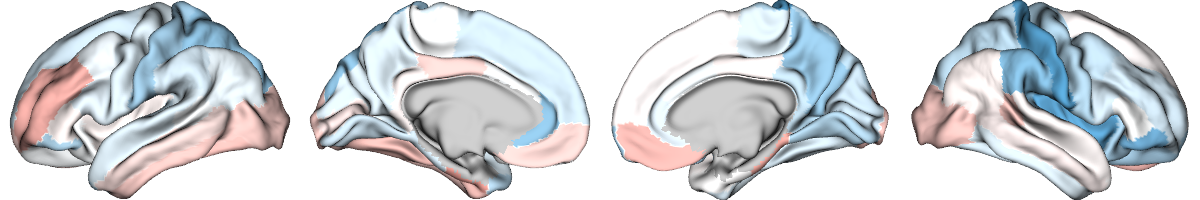

In [22]:
# plot t values
# label_text = ['sex_group_interaction']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

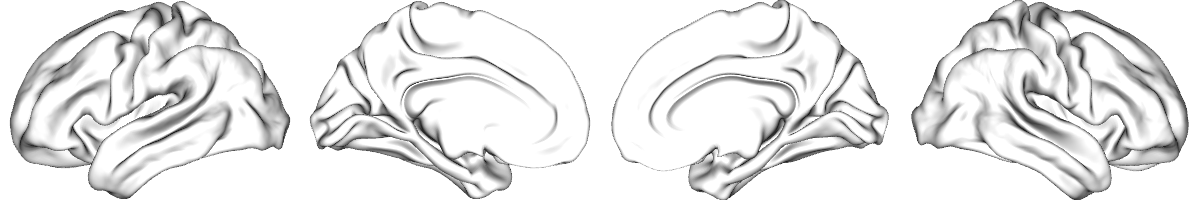

In [23]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [24]:
q_ctx_hc = pd.Series(result_dicts['q_tle_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [25]:
len(q_ctx_hc[q_ctx_hc < 0.05])

0

In [26]:
result_dicts['t_tle_ctx'][0].min(), result_dicts['t_tle_ctx'][0].max()

(-2.15815903008591, 1.493035059896673)

subcortical volume

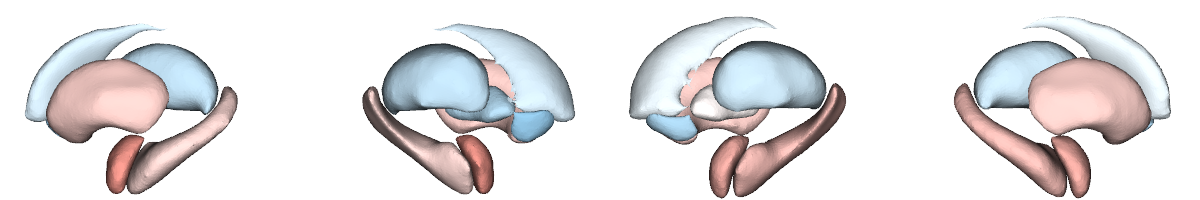

In [27]:
plot_subcortical(result_dicts['t_tle_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

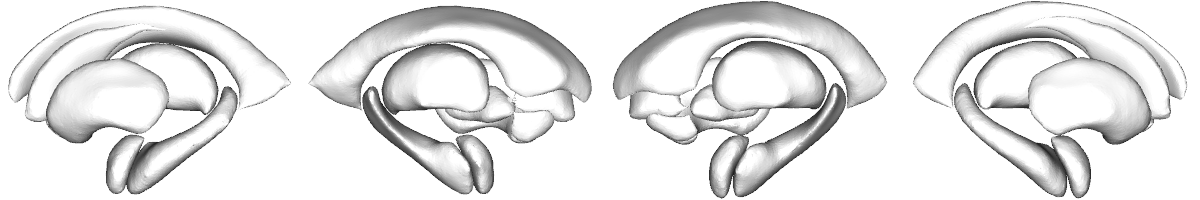

In [28]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1),interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [29]:
## Check which areas are significant in epilepsy
q_sv_inter = pd.Series(result_dicts['q_tle_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_inter[q_sv_inter < 0.05].index

Index([], dtype='object')

In [30]:
len(q_sv_inter[q_sv_inter < 0.05])

0

In [31]:
result_dicts['t_tle_sv'][0].min(), result_dicts['t_tle_sv'][0].max()

(-1.4521917476728823, 1.7496832242512557)

### Effect of sex and clinical variables interaction across cohorts

In [ ]:
## demographics
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle_durill.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle_durill.csv'), index_col=0)


In [34]:
# glm comparison
biomarker_datasets = {'ctx': {'tle': ctx_tle}, 'sv': {'tle': sv_tle}}

comparison_types = ['duration_sex_interaction', 'ao_sex_interaction']

results = {}

for epi in ['tle']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-09-02 17:02:12,644 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:02:12,683 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:02:12,711 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:02:12,743 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [35]:
# Reorganize results — TLE only

epi_types = ['tle']
biomarkers = ['ctx', 'sv']

comparison_types = ['duration_sex_interaction', 'ao_sex_interaction']

metric_map = {
    't': 't_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f'{metric_name}_{epi}_{biomarker}'] = values

In [ ]:
## Save 

metrics_to_save = ['t', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
comparison_types = ['duration_sex_interaction', 'ao_sex_interaction']
biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'TLE')
os.makedirs(output_base, exist_ok=True)

for row_idx, interaction_name in enumerate(comparison_types):

    interaction_dir = os.path.join(output_base, interaction_name)
    os.makedirs(interaction_dir, exist_ok=True)

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f'{metric}_tle_{biomarker}'

            if key not in result_dicts:
                continue

            values_all = result_dicts[key]
            values = values_all[row_idx, :]

            df = pd.DataFrame(values, index=index_cols, columns=[f'{metric}_value'])
            df['analysis'] = 'sex interaction with clinical variable'
            df['interaction'] = interaction_name
            df['predictor'] = ('disease duration' if interaction_name == 'duration_sex_interaction' else 'age of onset')
            df['diagnosis'] = 'TLE'
            df['metric'] = metric
            df['biomarker'] = biomarker

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(interaction_dir, out_name), index=True)

#### Sex duration interaction effects in cortical thickness in TLE

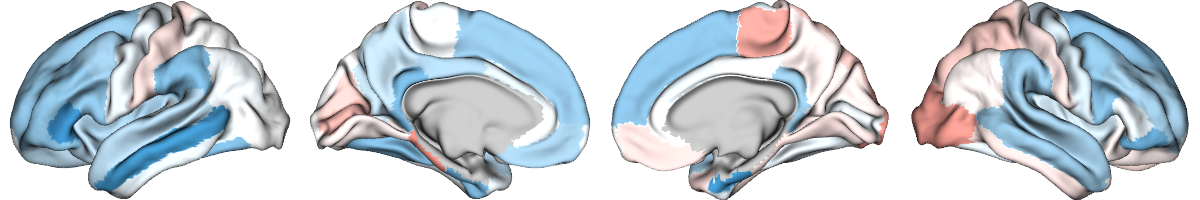

In [37]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

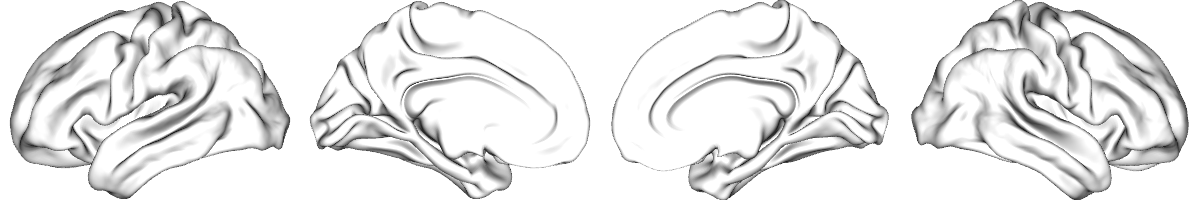

In [38]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [39]:
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [40]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [41]:
result_dicts['t_tle_ctx'][0].min(), result_dicts['t_tle_ctx'][0].max()

(-2.7471782949824393, 1.8331299893740862)

#### Sex * age of onset interaction effects in TLE

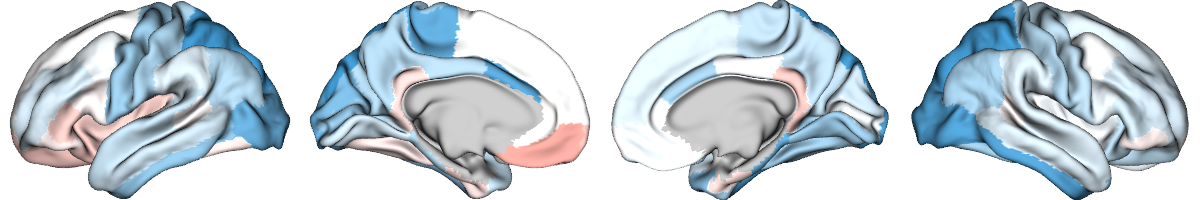

In [42]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

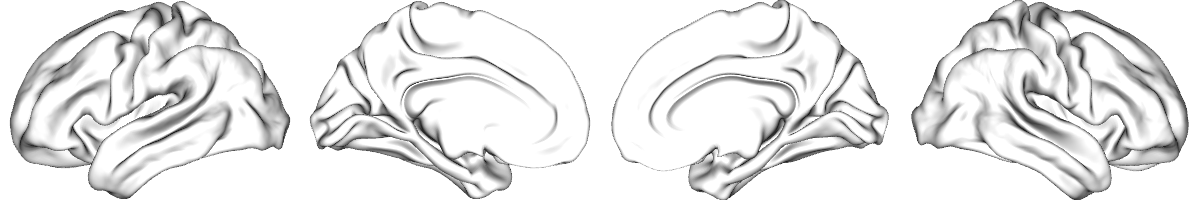

In [43]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [44]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][1], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [45]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [46]:
result_dicts['t_tle_ctx'][1].min(), result_dicts['t_tle_ctx'][1].max()

(-2.5357837288558196, 1.4528115333299512)

#### sex duration interaction effects in subcortical volume

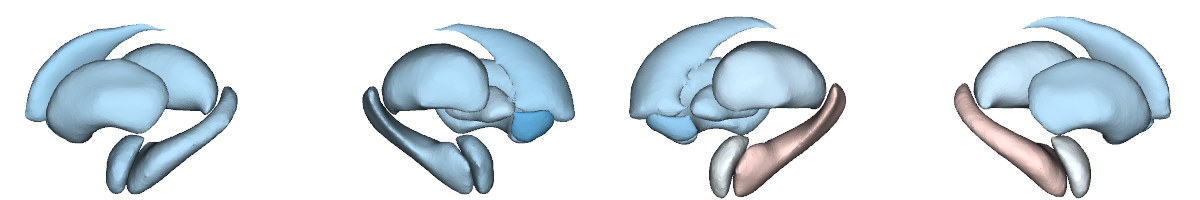

In [47]:
plot_subcortical(result_dicts['t_tle_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

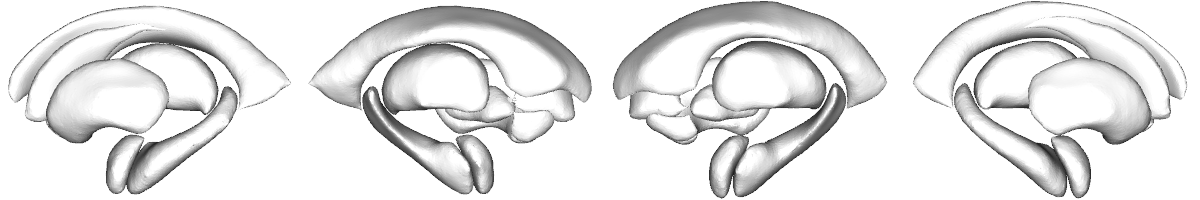

In [48]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [49]:
# sex * disease duration

q_sv_left = pd.Series(
    result_dicts["q_tle_sv"][0],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [50]:
result_dicts["t_tle_sv"][0].min(), result_dicts["t_tle_sv"][0].max()

(-2.1107354427929916, 0.6944189990595607)

#### Sex* age of onset interaction effects in TLE

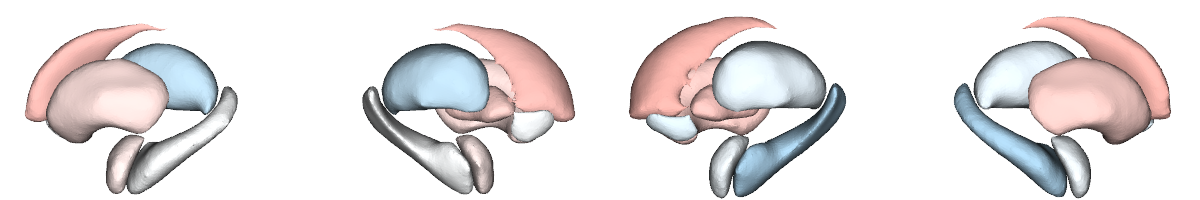

In [52]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

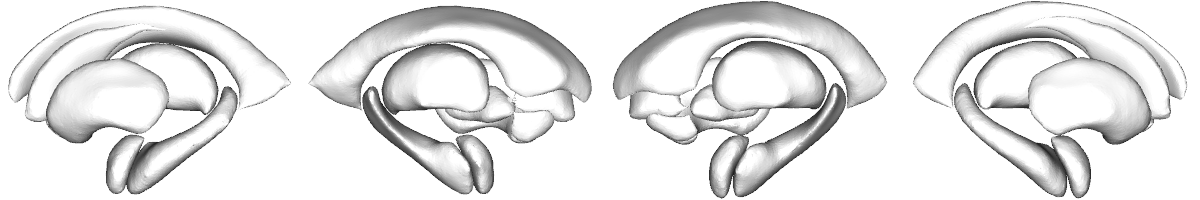

In [53]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [54]:
## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][1], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [55]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [56]:
result_dicts['t_tle_sv'][1].min(), result_dicts['t_tle_sv'][1].max()

(-1.0989924766612047, 1.2684634535724177)

## ECP dataset

In [57]:
data_dir = os.path.join(project_dir, 'data', 'ECP_data')
results_dir = os.path.join(project_dir, 'results', 'ECP_results')

## demographics
demo = pd.read_csv(os.path.join(data_dir, 'cov_cortex_matched.csv'), index_col=0)
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## metrics
ctx_tle = pd.read_csv(os.path.join(data_dir, 'ctx_ecp.csv'), index_col=0)
ctx_tle = ctx_tle.iloc[:, 2:]

sv_tle = pd.read_csv(os.path.join(data_dir, 'sv_ecp.csv'), index_col=0)
sv_tle = sv_tle.iloc[:, 2:]

### Effect of diagnosis-sex interaction across cohorts 

In [58]:
## glm comparison 
biomarker_datasets = {'ctx': {'tle': ctx_tle}, 'sv': {'tle': sv_tle}}

comparison_types = ['sex_group_interaction']

results = {}

for epi in ['tle']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col="Age",
                sex_col="Sex", icv_col="ICV", group_col="Dx")

2026-09-02 17:15:42,375 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:15:42,381 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:15:42,386 - brainstat - WARNING - interact has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:15:42,408 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical va

2026-09-02 17:15:42,413 - brainstat - WARNING - interact has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.


In [59]:
# Reorganize results 

epi_types = ['tle']
biomarkers = ['ctx', 'sv']

comparison_types = ['sex_group_interaction']

metric_map = {
    't': 't_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([
                np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f'{metric_name}_{epi}_{biomarker}'] = values

In [ ]:
## Save

metrics_to_save = ['t', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'TLE')
os.makedirs(output_base, exist_ok=True)

for biomarker in biomarkers:
    index_cols = biomarker_index_map[biomarker]

    for metric in metrics_to_save:
        key = f'{metric}_tle_{biomarker}'

        if key not in result_dicts:
            continue

        values_all = result_dicts[key]
        values = values_all[0, :]

        df = pd.DataFrame(values, index=index_cols, columns=[f'{metric}_value'])
        df['analysis'] = 'sex × diagnosis interaction'
        df['interaction'] = 'sex_group_interaction'
        df['diagnosis'] = 'TLE'
        df['metric'] = metric
        df['biomarker'] = biomarker

        out_name = f'{metric}_{biomarker}.csv'
        df.to_csv(os.path.join(output_base, out_name), index=True)

#### Sex effects in interaction in cortical thickness in TLE

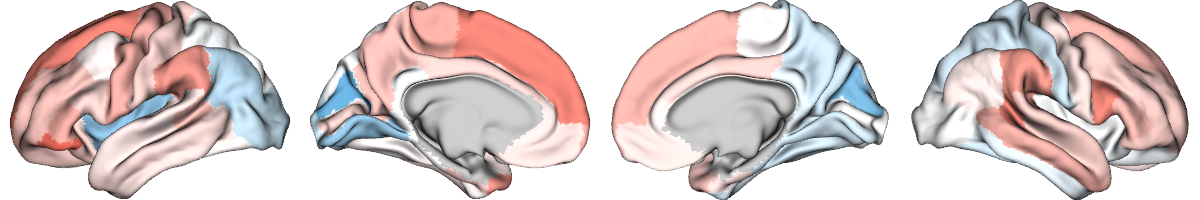

In [62]:
# plot t values
# label_text = ['sex_group_interaction']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

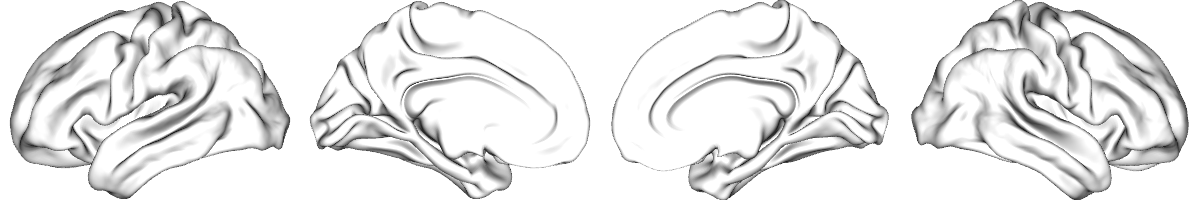

In [63]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [64]:
## Check which areas are significant in epilepsy
q_ctx_hc = pd.Series(result_dicts['q_tle_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [65]:
len(q_ctx_hc[q_ctx_hc < 0.05])

0

In [66]:
result_dicts['t_tle_ctx'][0].min(), result_dicts['t_tle_ctx'][0].max()

(-1.9631718980928838, 2.473690174007474)

#### Subcortical volume

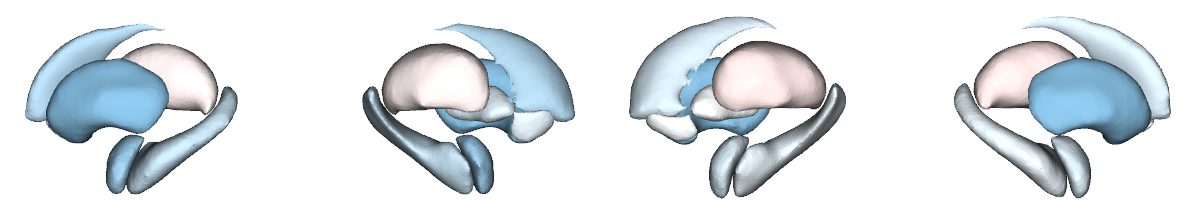

In [67]:
# plot t values
# ['sex_group_interaction']

plot_subcortical(result_dicts['t_tle_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

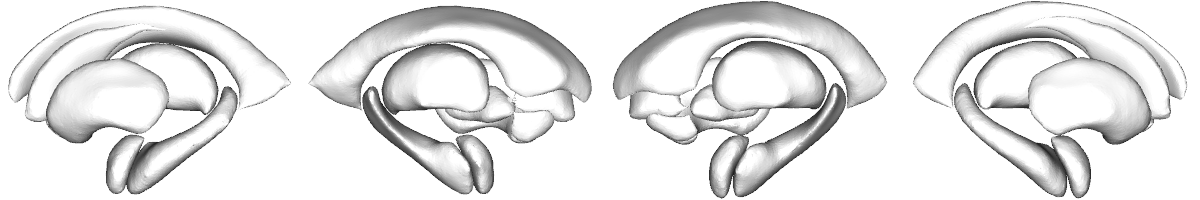

In [68]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1),interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [69]:
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [71]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [72]:
result_dicts['t_tle_sv'][0].min(), result_dicts['t_tle_sv'][0].max()

(-1.5876265453216267, 0.4040881327361393)

### Effect of sex and clinical variables interaction across cohorts

In [73]:
## demographics
demo = pd.read_csv(os.path.join(data_dir, 'cov_cortex_matched.csv'), index_col=0)
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')
demo = demo.dropna(subset=['ao'])

## metrics
ctx_tle = pd.read_csv(os.path.join(data_dir, 'ctx_ecp.csv'), index_col=0)
ctx_tle = ctx_tle.iloc[:, 2:]
ctx_tle = ctx_tle.loc[demo.index]

sv_tle = pd.read_csv(os.path.join(data_dir, 'sv_ecp.csv'), index_col=0)
sv_tle = sv_tle.iloc[:, 2:]
sv_tle = sv_tle.loc[demo.index]


In [74]:
# glm comparison
biomarker_datasets = {'ctx': {'tle': ctx_tle}, 'sv': {'tle': sv_tle}}

comparison_types = ['duration_sex_interaction', 'ao_sex_interaction']

results = {}
for epi in ['tle']:  
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-09-02 17:24:44,593 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:24:44,615 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:24:44,633 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:24:44,653 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [75]:
# Reorganize results 

epi_types = ['tle']
biomarkers = ['ctx', 'sv']

comparison_types = ['duration_sex_interaction', 'ao_sex_interaction']

metric_map = {
    't': 't_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f'{metric_name}_{epi}_{biomarker}'] = values

In [ ]:
## Save

metrics_to_save = ['t', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
comparison_types = ['duration_sex_interaction', 'ao_sex_interaction']
biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'TLE')
os.makedirs(output_base, exist_ok=True)

for row_idx, interaction_name in enumerate(comparison_types):

    interaction_dir = os.path.join(output_base, interaction_name)
    os.makedirs(interaction_dir, exist_ok=True)

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f'{metric}_tle_{biomarker}'

            if key not in result_dicts:
                continue

            values_all = result_dicts[key]
            values = values_all[row_idx, :]

            df = pd.DataFrame(values, index=index_cols, columns=[f'{metric}_value'])
            df['analysis'] = 'sex interaction with clinical variable'
            df['interaction'] = interaction_name

            df['predictor'] = ('disease duration' if interaction_name == 'duration_sex_interaction' else 'age of onset')
            df['diagnosis'] = 'TLE'
            df['metric'] = metric
            df['biomarker'] = biomarker

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(interaction_dir, out_name), index=True)

#### Sex duration interaction effects in cortical thickness in TLE

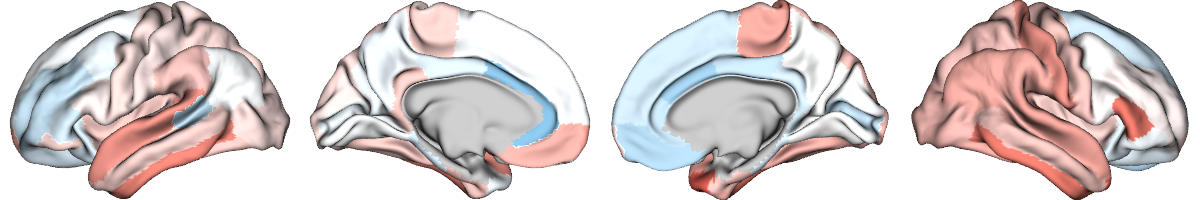

In [77]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

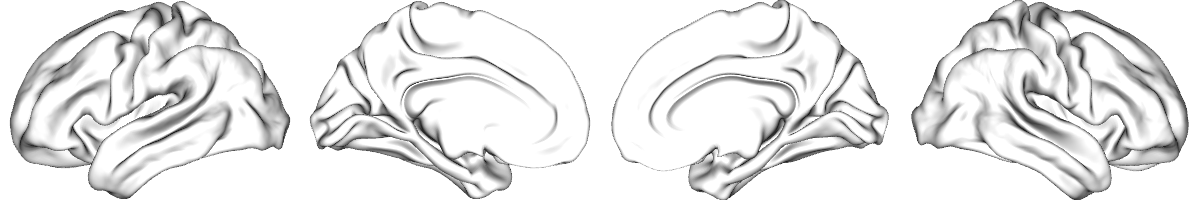

In [78]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [79]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [80]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [81]:
result_dicts['t_tle_ctx'][0].min(), result_dicts['t_tle_ctx'][0].max()

(-1.5648696144661853, 2.7474272472617667)

#### Sex*age of onset interaction effects

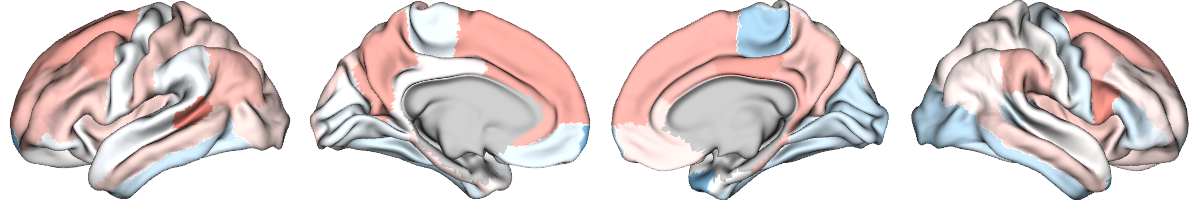

In [82]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

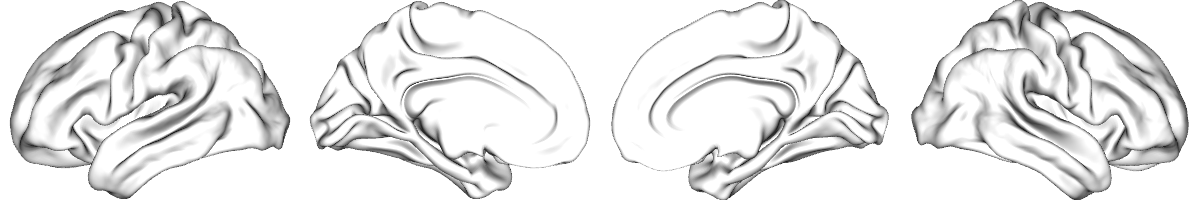

In [83]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [84]:
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][1], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [85]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [86]:
result_dicts['t_tle_ctx'][1].min(), result_dicts['t_tle_ctx'][1].max()

(-1.7815783918054553, 2.0265736316108813)

#### sex duration interaction effects in subcortical volume

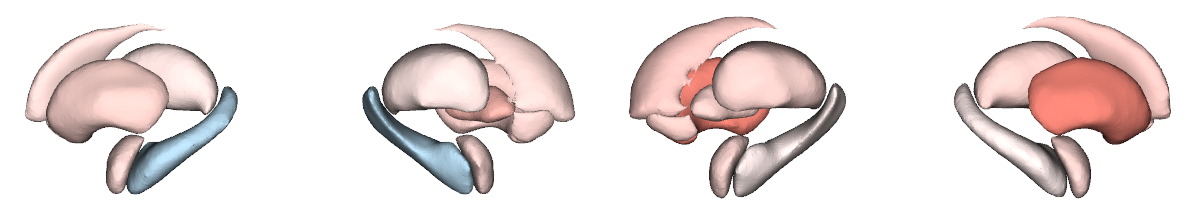

In [88]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))


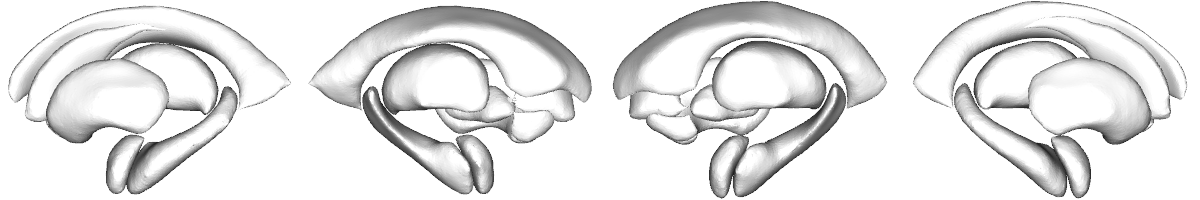

In [89]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [90]:
# sex * disease duration 

q_sv_left = pd.Series(
    result_dicts["q_tle_sv"][0],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [91]:
result_dicts["t_tle_sv"][0].min(), result_dicts["t_tle_sv"][0].max()

(-1.0075093406843305, 2.0946654443900012)

#### Sex age of onset interaction effects

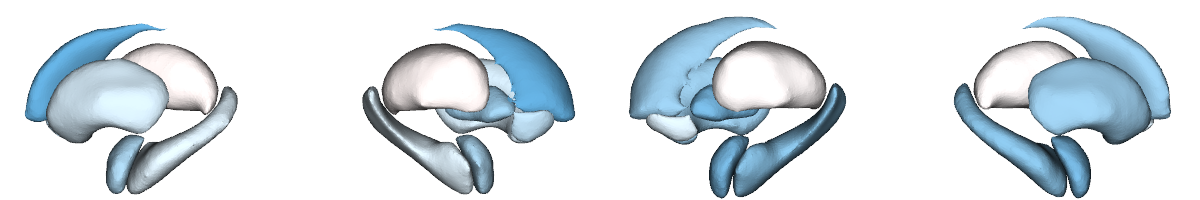

In [92]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

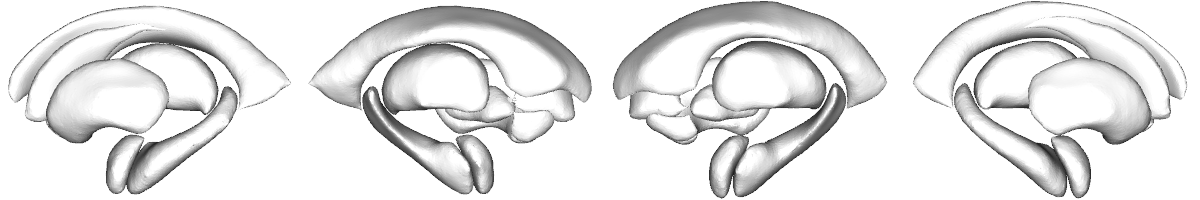

In [93]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [94]:
q_sv_hc = pd.Series(result_dicts['q_tle_sv'][1], index=sv_tle.columns, name='pFDR')
q_sv_hc[q_sv_hc < 0.05].index

Index([], dtype='object')

In [95]:
len(q_sv_hc[q_sv_hc < 0.05])

0

In [96]:
result_dicts['t_tle_sv'][1].min(), result_dicts['t_tle_sv'][1].max()

(-2.095122555097941, 0.1625545045234283)

## MNI dataset

In [98]:
data_dir = os.path.join(project_dir, 'data', 'MNI_data')
results_dir = os.path.join(project_dir, 'results', 'MNI_results')

In [99]:
## demographics
demo = pd.read_csv(os.path.join(data_dir, 'demo.csv'), index_col=0)
# demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## metrics
ctx_tle = pd.read_csv(os.path.join(data_dir, 'ctx.csv'), index_col=0)
ctx_tle = ctx_tle.iloc[:, 1:]

sv_tle = pd.read_csv(os.path.join(data_dir, 'sv.csv'), index_col=0)
sv_tle = sv_tle.iloc[:, 1:]

### Effect of sex and diagnosis-sex interaction across cohorts

In [100]:
## glm comparison 
biomarker_datasets = {'ctx': {'tle': ctx_tle}, 'sv': {'tle': sv_tle}}

comparison_types = ['sex_group_interaction']

results = {}

for epi in ['tle']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col="Age",
                sex_col="Sex", icv_col="ICV", group_col="Dx")

2026-09-02 17:36:40,782 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:36:40,791 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:36:40,799 - brainstat - WARNING - interact has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:36:40,826 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical va

In [101]:
# Reorganize results — TLE only

epi_types = ['tle']
biomarkers = ['ctx', 'sv']

comparison_types = ['sex_group_interaction']

metric_map = {
    't': 't_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f'{metric_name}_{epi}_{biomarker}'] = values

In [ ]:
## Save 

metrics_to_save = ['t', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'TLE')
os.makedirs(output_base, exist_ok=True)


for biomarker in biomarkers:
    index_cols = biomarker_index_map[biomarker]

    for metric in metrics_to_save:
        key = f'{metric}_tle_{biomarker}'

        if key not in result_dicts:
            continue

        values_all = result_dicts[key]
        values = values_all[0, :]

        df = pd.DataFrame(values, index=index_cols, columns=[f'{metric}_value'])
        df['analysis'] = 'sex × diagnosis interaction'
        df['interaction'] = 'sex_group_interaction'
        df['diagnosis'] = 'TLE'
        df['metric'] = metric
        df['biomarker'] = biomarker

        out_name = f'{metric}_{biomarker}.csv'
        df.to_csv(os.path.join(output_base, out_name), index=True)

Sex effects in interaction in cortical thickness in TLE

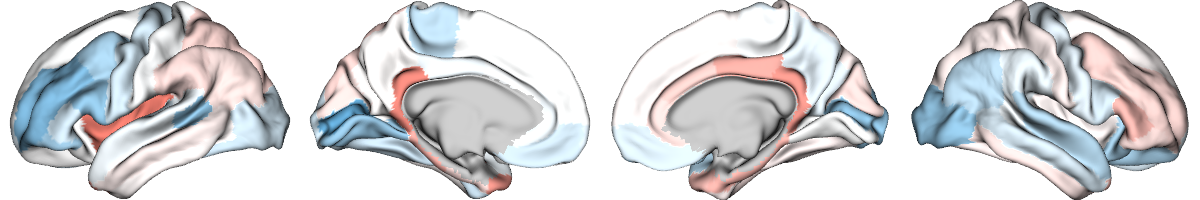

In [103]:
# plot t values
# label_text = ['sex_group_interaction']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

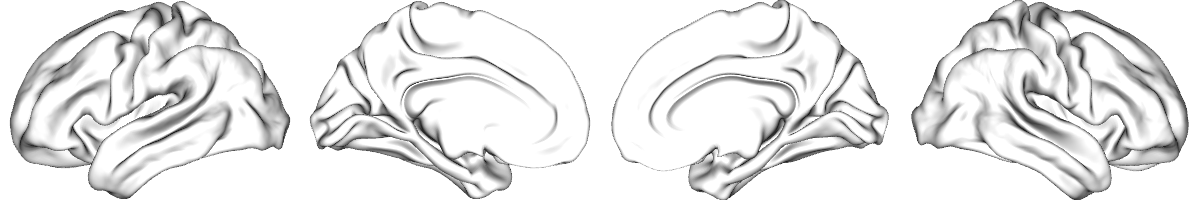

In [104]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [106]:
q_ctx_hc = pd.Series(result_dicts['q_tle_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [107]:
result_dicts['t_tle_ctx'][0].min(), result_dicts['t_tle_ctx'][0].max()

(-2.0265968981284157, 2.1603078904804445)

#### subcortical volume

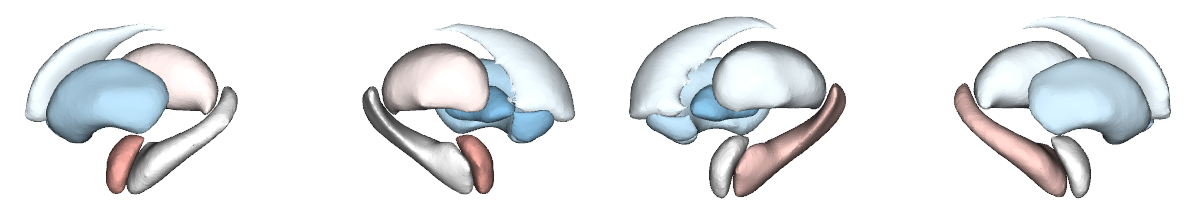

In [109]:
plot_subcortical(result_dicts['t_tle_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

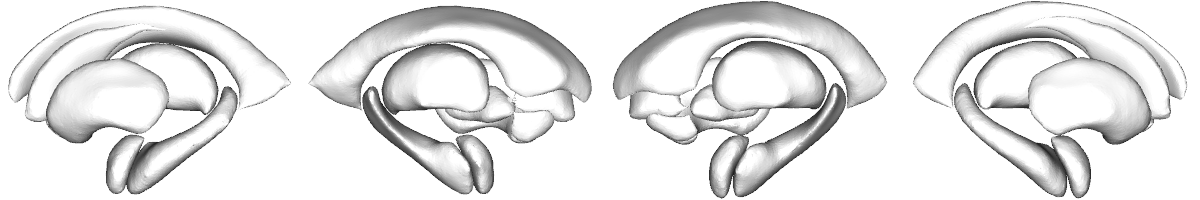

In [110]:
# plot p-sig regions

sig_mask = np.where(result_dicts['q_tle_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1),interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [111]:
q_sv_inter = pd.Series(result_dicts['q_tle_sv'][0], index=sv_tle.columns, name='pFDR')
q_sv_inter[q_sv_inter < 0.05].index

Index([], dtype='object')

In [112]:
len(q_sv_inter[q_sv_inter < 0.05])

0

In [113]:
result_dicts['t_tle_sv'][0].min(), result_dicts['t_tle_sv'][0].max()

(-1.6408031394389018, 1.4228839279712684)

### Effect of sex and clinical variables interaction across cohorts

In [114]:
## demographics
demo = pd.read_csv(os.path.join(data_dir, 'demo.csv'), index_col=0)
# demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')
demo = demo.dropna(subset=['ao'])

## metrics
ctx_tle = pd.read_csv(os.path.join(data_dir, 'ctx.csv'), index_col=0)
ctx_tle = ctx_tle.iloc[:, 1:]
ctx_tle = ctx_tle.loc[demo.index]

sv_tle = pd.read_csv(os.path.join(data_dir, 'sv.csv'), index_col=0)
sv_tle = sv_tle.iloc[:, 1:]
sv_tle = sv_tle.loc[demo.index]

In [115]:
# glm comparison
biomarker_datasets = {'ctx': {'tle': ctx_tle}, 'sv': {'tle': sv_tle}}

comparison_types = ['duration_sex_interaction', 'ao_sex_interaction']

results = {}
for epi in ['tle']:  
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-09-02 17:44:24,056 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:44:24,088 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:44:24,120 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-09-02 17:44:24,154 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [116]:
# Reorganize results 

epi_types = ['tle']
biomarkers = ['ctx', 'sv']

comparison_types = ['duration_sex_interaction', 'ao_sex_interaction']

metric_map = {
    't': 't_values', 'q': 'q_values',
    'beta': 'beta', 'ci_lower': 'ci_lower', 'ci_upper': 'ci_upper'
}

result_dicts = {}

for epi in epi_types:
    for biomarker in biomarkers:
        for metric_name, result_key in metric_map.items():

            values = np.vstack([np.asarray(results[epi][biomarker][comp][result_key]).flatten()
                for comp in comparison_types
            ])

            result_dicts[f'{metric_name}_{epi}_{biomarker}'] = values

In [ ]:
## Save 

metrics_to_save = ['t', 'q', 'beta', 'ci_lower', 'ci_upper']
biomarkers = ['ctx', 'sv']
comparison_types = ['duration_sex_interaction', 'ao_sex_interaction']
biomarker_index_map = {'ctx': ctx_tle.columns, 'sv': sv_tle.columns}

output_base = os.path.join(results_dir, '...', 'TLE')
os.makedirs(output_base, exist_ok=True)

for row_idx, interaction_name in enumerate(comparison_types):
    interaction_dir = os.path.join(output_base, interaction_name)
    os.makedirs(interaction_dir, exist_ok=True)

    for biomarker in biomarkers:
        index_cols = biomarker_index_map[biomarker]

        for metric in metrics_to_save:
            key = f'{metric}_tle_{biomarker}'

            if key not in result_dicts:
                continue

            values_all = result_dicts[key]
            values = values_all[row_idx, :]

            df = pd.DataFrame(values, index=index_cols, columns=[f'{metric}_value'])
            df['analysis'] = 'sex interaction with clinical variable'
            df['interaction'] = interaction_name
            df['predictor'] = ('disease duration' if interaction_name == 'duration_sex_interaction' else 'age of onset')
            df['diagnosis'] = 'TLE'
            df['metric'] = metric
            df['biomarker'] = biomarker

            out_name = f'{metric}_{biomarker}.csv'
            df.to_csv(os.path.join(interaction_dir, out_name), index=True)

#### Sex duration interaction effects in cortical thickness in TLE

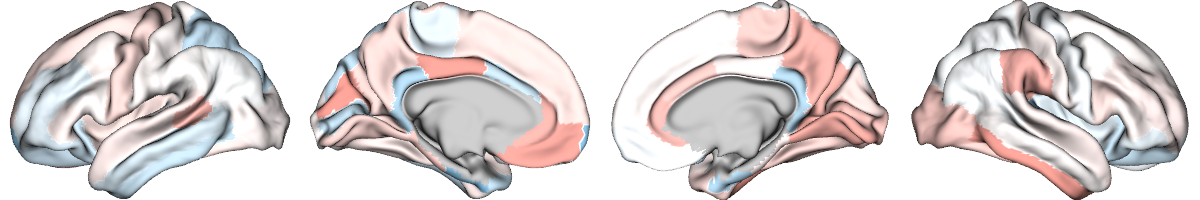

In [118]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'][0], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

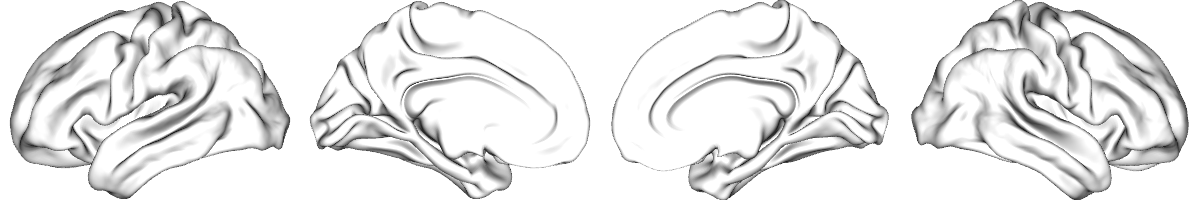

In [119]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][0], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [120]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][0], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [121]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [122]:
result_dicts['t_tle_ctx'][0].min(), result_dicts['t_tle_ctx'][0].max()

(-1.5853723534873447, 1.6792056394480575)

#### Sex*age of onset interaction effects

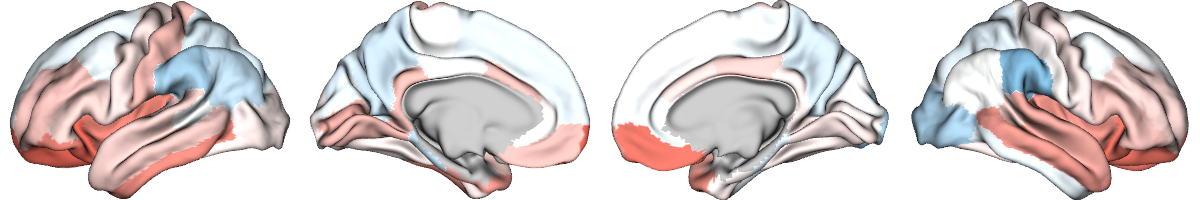

In [123]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

t_ctx_surf = parcel_to_surface(result_dicts['t_tle_ctx'][1], 'aparc_conte69')
t_ctx_surf[t_ctx_surf==0] = np.nan

plot_cortical(array_name=t_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

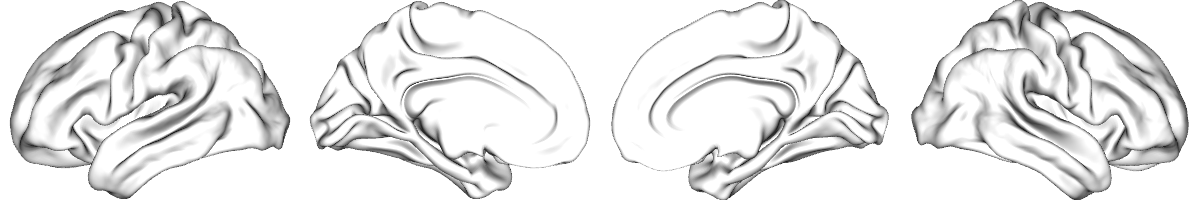

In [124]:
# plot p-sig regions

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [125]:
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][1], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [126]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [127]:
result_dicts['t_tle_ctx'][1].min(), result_dicts['t_tle_ctx'][1].max()

(-1.6156375043549958, 2.7062844005565694)

#### sex duration interaction effects in subcortical volume

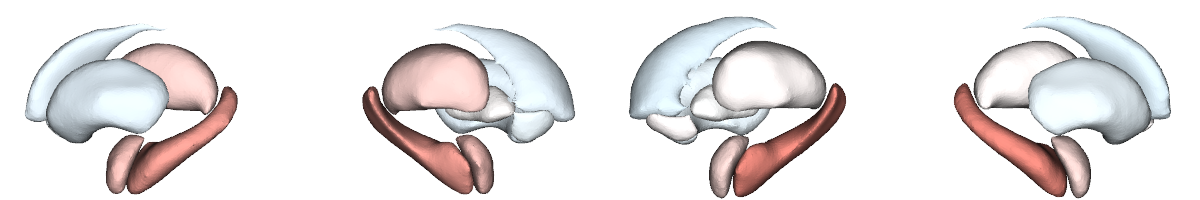

In [128]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_sv'][0], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

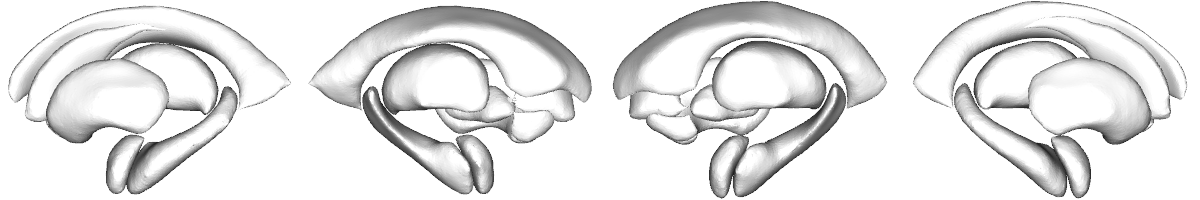

In [129]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][0] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [130]:
# sex * disease duration

q_sv_left = pd.Series(
    result_dicts["q_tle_sv"][0],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [131]:
result_dicts["t_tle_sv"][0].min(), result_dicts["t_tle_sv"][0].max()

(-0.501017659892422, 1.9317393033476418)

#### Sex* age of onset interaction effects in TLE

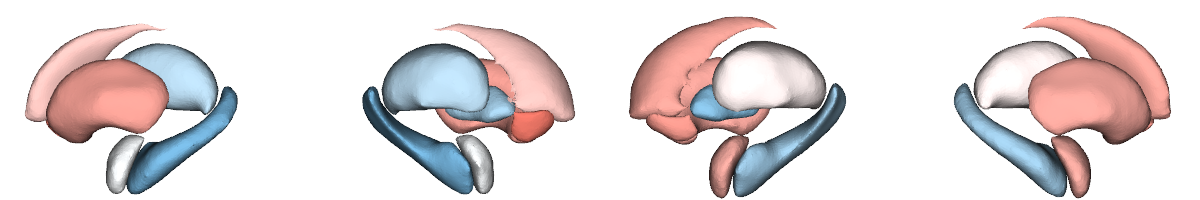

In [132]:
# plot t values
# label_text = ['sex * durill', 'sex * ao']

plot_subcortical(result_dicts['t_tle_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-5, 5))

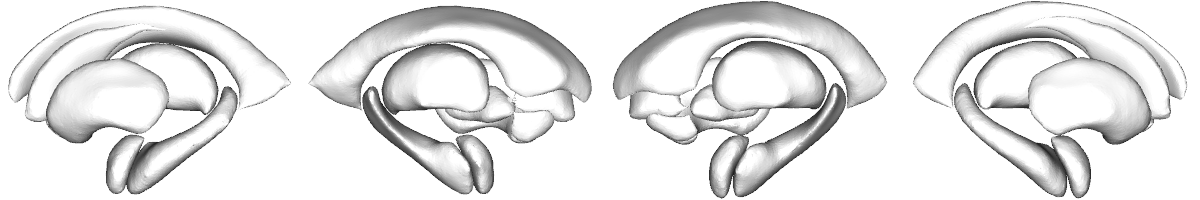

In [133]:
sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [134]:
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][1], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [135]:
result_dicts['t_tle_sv'][1].min(), result_dicts['t_tle_sv'][1].max()

(-1.802101893970435, 2.270738949877289)